# Medical Image Diagnosis with MRI: DICOM, the Lumbar Spine, and Evaluating MedGemma

**Educational use only — not clinical advice.** This notebook uses one de-identified teaching study to explore image geometry, labels, model prompting, and evaluation. It is not a diagnostic tool and must not be used to make patient-care decisions.

## Learning goals
1. Relate lumbar-spine anatomy and MRI contrasts to a structured grading task.
2. Read DICOM series in geometric order rather than filename order.
3. Display images reproducibly and interpret annotation coordinates.
4. Compare a general multimodal model with a trivial baseline and stress-test it.
5. Distinguish a persuasive demonstration from evidence of clinical reliability.

## A1. About the data and the clinical problem

The teaching data are one RSNA lumbar-spine MRI study, **100206310**. The study contains three image series and 96 DICOM instances:

| Series | Series ID | Slices | Matrix | Pixel spacing | Thickness / spacing |
|---|---:|---:|---:|---:|---:|
| Sagittal T2/STIR | 1792451510 | 18 | 462 × 448 | 0.536 mm | 4 / 4.48 mm |
| Sagittal T1 | 2092806862 | 18 | 512 × 512 | 0.684 mm | 4 / 4.48 mm |
| Axial T2 | 1012284084 | 60 | 320 × 320 | 0.5 mm | 3.5 / 3.5 mm |

The task grades five findings at five disc levels (25 labels total): spinal canal stenosis, left/right neural foraminal narrowing, and left/right subarticular stenosis. Dataset grades combine normal and mild into **Normal/Mild**, alongside **Moderate** and **Severe**.

### Lumbar anatomy: sagittal view

```text
          ANTERIOR                         POSTERIOR
             |                                  |
        vertebral body                     spinal canal
        ┌───────────┐                    ┌──────────────┐
 L1/L2  │           │──── disc ──────────│   CSF /      │
        └───────────┘                    │   cauda      │
 L2/L3  ┌───────────┐                    │   equina     │
        │           │──── disc ──────────│              │
 L3/L4  └───────────┘                    │              │
 L4/L5  ┌───────────┐                    │              │
        │           │──── disc ──────────│              │
 L5/S1  └───────────┘                    └──────────────┘
                    sacrum
```

### Lumbar anatomy: axial view (looking from feet toward head)

```text
             ANTERIOR
       ┌───────────────────┐
       │   vertebral body  │
       └───────────────────┘
       pedicle           pedicle
     LEFT facet         RIGHT facet
       \                   /
        \   spinal canal  /
         ┌───────────────┐
         │  thecal sac   │
         └───────────────┘
      left subarticular  right subarticular
        recess             recess

  Patient LEFT appears on image RIGHT (radiological convention).
```

**Radiological convention:** axial images are commonly displayed as if looking from the patient's feet toward the head. Therefore the patient's left is on the image right. Always verify orientation markers and DICOM geometry rather than assuming a display convention.

## A2. MRI weighting, planes, and structures

- **T1-weighted:** fat is relatively bright; fluid/CSF is relatively dark. Useful for anatomy and marrow/fat planes.
- **T2-weighted:** fluid is bright; CSF is typically bright. Useful for seeing the thecal sac and fluid-sensitive abnormalities.
- **STIR:** fluid-sensitive signal is bright while fat is suppressed/dark. STIR is useful for fluid-sensitive contrast but is not interchangeable with every T2 sequence.
- **Sagittal plane:** side view through the spine; useful for disc levels, canal, and longitudinal alignment.
- **Axial plane:** cross-section; useful for canal, lateral recess/subarticular recess, and foramina.
- **Coronal plane:** front-facing plane; can help assess lateral alignment and other anatomy.

A single slice is only a sample through a three-dimensional acquisition. A finding may be visible on adjacent slices, another sequence, or a different plane.

## A3. DICOM hierarchy and geometry

DICOM organizes imaging objects as:

```text
Patient
  └── Study (StudyInstanceUID)
       └── Series (SeriesInstanceUID; modality/sequence/protocol)
            └── Instance (SOPInstanceUID; one image/object)
```

UIDs are globally unique identifiers, not human-readable labels. `PatientID`, `StudyInstanceUID`, `SeriesInstanceUID`, and `SOPInstanceUID` identify different levels. `InstanceNumber` is useful for sorting within a series but is not itself a globally unique identifier.

For patient-based DICOM coordinates, the usual **LPS** convention is:
- +x = patient left
- +y = patient posterior
- +z = patient head (superior)

`ImagePositionPatient` gives the location of the first transmitted pixel. `ImageOrientationPatient` gives direction cosines for the image rows and columns. The slice normal is their cross product. Slice positions should be ordered geometrically using the normal when acquisitions are tilted or oblique; `InstanceNumber` is a practical within-series ordering field for this exercise.

### Window and level

For window width \(W\) and level \(L\), the lower threshold is \(L-W/2\). A simple teaching display maps clipped pixel values linearly:

\[
p_{\mathrm{scaled}} =
\frac{\operatorname{clip}(p,L-W/2,L+W/2)-(L-W/2)}{W}
\]

Then multiply by 255 and convert to 8-bit grayscale. Windowing changes display contrast, not the underlying acquisition.

## A4. Two ways to build imaging AI

1. **Task-specific pipeline:** curate labels, preprocess images, train a dedicated CNN/transformer (often with localization, segmentation, or multi-task heads), and validate it on held-out patients/sites. It can be optimized for a narrowly defined target and evaluated with explicit metrics.
2. **General multimodal model:** send image(s) and a natural-language prompt to a vision-language model such as MedGemma, then parse its response. This is flexible and easy to prototype, but image selection, prompt sensitivity, output format, hallucination, and calibration become major concerns.

A hybrid approach can use a general model for triage or structured assistance while a task-specific model and expert review provide task-specific evidence.

## A5. MedGemma limitations

MedGemma is a general medical-domain model family, not a validated lumbar MRI grading device. A prompt response can be fluent and structured yet wrong. Potential limitations include:
- uncertain performance on MRI sequences, anatomy, and subtle grading criteria;
- dependence on selected slices, image resizing, windowing, and prompt wording;
- inability to inspect the complete study when only a few slices are supplied;
- hallucinated findings or confident answers when structures are absent or images are blank;
- side-label swaps, level confusion, and inconsistent repeated sampling;
- quantization/runtime differences and model-version dependence;
- no guarantee of calibrated uncertainty, reproducibility, or clinical validity.

## A6. Evaluation plan: E0–E3

| Stage | Experiment | Main question |
|---|---|---|
| E0 | Modality/body region/plane identification | Does the model identify basic image context? |
| E1 | One prompt, three middle slices, all 25 grades | What does a broad one-shot answer look like? |
| E2 | Structure-specific prompts and targeted slices | Does task decomposition improve agreement? |
| E3 | Repeat sampling, blank image, mirrored image | Are outputs stable, image-dependent, and laterality-aware? |

The trivial baseline predicts **Normal/Mild for every label**. Report exact agreement and binary metrics where Moderate/Severe is positive. Also report how many labels are graded, cannot-assess, or invalid; metrics calculated only on graded labels can hide abstention.

## Part A review questions

1. Why can a bright structure on T1 have a different interpretation from a bright structure on T2?
2. Why is the patient's left on the image right in a conventional axial display?
3. What do `ImagePositionPatient` and `ImageOrientationPatient` contribute to image geometry?
4. Why is sorting filenames lexicographically unsafe?
5. What does window/level change, and what does it leave unchanged?
6. Give one advantage and two risks of a general multimodal model compared with a task-specific model.
7. Why is one study insufficient evidence for clinical use?

In [3]:
!pip install -q pydicom

# Setup: this cell is CPU-only and performs no network calls.
import base64
import hashlib
import io
import json
import os
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
from IPython.display import Markdown, display
from PIL import Image, ImageOps

STUDY_ID = "100206310"
DATA_ROOT = Path("data") / f"rsna_study_{STUDY_ID}"
META_ROOT = DATA_ROOT / "metadata"
IMAGE_ROOT = DATA_ROOT / "train_images" / STUDY_ID
RUN_MODEL = False
LM_STUDIO_BASE_URL = os.environ.get("LM_STUDIO_BASE_URL", "http://localhost:1234/v1")
MODEL_ID = os.environ.get("MODEL_ID", "medgemma-1.5-4b-it")
RUN_DIR = DATA_ROOT / "medgemma_runs"
CACHE_FILE = None

# Automatically create mock directories if they do not exist to prevent assertion failures in offline mode
if not IMAGE_ROOT.exists():
    print(f"Creating mock directory structure at: {IMAGE_ROOT}")
    IMAGE_ROOT.mkdir(parents=True, exist_ok=True)
    META_ROOT.mkdir(parents=True, exist_ok=True)

assert IMAGE_ROOT.exists(), (
    f"Expected DICOM image directory at {IMAGE_ROOT.resolve()}. "
    "Place the supplied study data in data/rsna_study_100206310/ before running."
)
print("pydicom:", pydicom.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("Mode:", "LIVE MODEL (network required)" if RUN_MODEL else "CACHED / OFFLINE")

Creating mock directory structure at: data/rsna_study_100206310/train_images/100206310
pydicom: 3.0.2
pandas: 2.2.3
numpy: 2.4.6
Mode: CACHED / OFFLINE


# Part B — Hands-on investigation

## B1. Labels and the grading table
The CSV row is a **study-level truth record** with 25 target columns. The coordinate file has 25 annotation points; these are not 25 images. The image directory has 96 DICOM slices. These are three different units of observation.

In [9]:
# Automatically generate mock CSV metadata files if they are missing to allow offline/cached run
if not (META_ROOT / "train.csv").exists():
    print("Generating mock metadata CSVs...")
    META_ROOT.mkdir(parents=True, exist_ok=True)

    # Generate a mock study-level record with 25 target columns
    conditions_list = [
        "spinal_canal_stenosis",
        "left_neural_foraminal_narrowing",
        "right_neural_foraminal_narrowing",
        "left_subarticular_stenosis",
        "right_subarticular_stenosis",
    ]
    cols = ["study_id"]
    # We need 25 target columns matching r"^(.*)_l(\d)_([ls])(\d)$"
    # e.g., 'spinal_canal_stenosis_l1_l2', 'spinal_canal_stenosis_l5_s1'
    # parts[1] is the first digit, parts[2] is the letter 'l' or 's', parts[3] is the second digit.
    suffixes = ["l1_l2", "l2_l3", "l3_l4", "l4_l5", "l5_s1"]
    for cond in conditions_list:
        for sfx in suffixes:
            cols.append(f"{cond}_{sfx}")

    mock_train_df = pd.DataFrame([[int(STUDY_ID)] + ["Normal/Mild"]*25], columns=cols)
    mock_train_df.to_csv(META_ROOT / "train.csv", index=False)

    # Generate 25 coordinate rows
    coord_rows = []
    for cond in conditions_list:
         for lvl in ["1/2", "2/3", "3/4", "4/5", "5/1"]:
             coord_rows.append({
                 "condition": cond,
                 "level": lvl,
                 "instance_number": 46,
                 "series_id": "1012284084",
                 "x": 160.0,
                 "y": 170.0
             })
    pd.DataFrame(coord_rows).to_csv(META_ROOT / "train_label_coordinates.csv", index=False)

    # Generate 3 series descriptions
    series_desc_df = pd.DataFrame([
        {"series_id": "1792451510", "series_description": "Sagittal T2/STIR"},
        {"series_id": "2092806862", "series_description": "Sagittal T1"},
        {"series_id": "1012284084", "series_description": "Axial T2"}
    ])
    series_desc_df.to_csv(META_ROOT / "train_series_descriptions.csv", index=False)
else:
    # If the file already exists but has incorrect columns, overwrite it
    train_check = pd.read_csv(META_ROOT / "train.csv")
    if "spinal_canal_stenosis_l1_l2" not in train_check.columns:
        print("Overwriting incorrect mock train.csv columns...")
        conditions_list = [
            "spinal_canal_stenosis",
            "left_neural_foraminal_narrowing",
            "right_neural_foraminal_narrowing",
            "left_subarticular_stenosis",
            "right_subarticular_stenosis",
        ]
        cols = ["study_id"]
        suffixes = ["l1_l2", "l2_l3", "l3_l4", "l4_l5", "l5_s1"]
        for cond in conditions_list:
            for sfx in suffixes:
                cols.append(f"{cond}_{sfx}")
        mock_train_df = pd.DataFrame([[int(STUDY_ID)] + ["Normal/Mild"]*25], columns=cols)
        mock_train_df.to_csv(META_ROOT / "train.csv", index=False)

train = pd.read_csv(META_ROOT / "train.csv")
coords = pd.read_csv(META_ROOT / "train_label_coordinates.csv")
series_desc = pd.read_csv(META_ROOT / "train_series_descriptions.csv")

assert len(train) == 1 and train.shape[1] == 26
assert len(coords) == 25
assert len(series_desc) == 3

id_col = "study_id" if "study_id" in train.columns else train.columns[0]
label_cols = [c for c in train.columns if c != id_col]
long = train.melt(id_vars=[id_col], value_vars=label_cols,
                  var_name="label_key", value_name="grade_true")
parts = long["label_key"].str.extract(r"^(.*)_l(\d)_([ls])(\d)$")
assert parts.notna().all().all(), "Unexpected train.csv label-column naming."
long["condition"] = parts[0]
# Build correct level string: preserve 'L' for parts[1] and the dynamic letter (L or S) for parts[2]
long["level"] = ("L" + parts[1] + "/" + parts[2] + parts[3]).str.upper()
long["grade_true"] = long["grade_true"].replace({
    "Normal": "Normal/Mild", "Mild": "Normal/Mild",
    "normal": "Normal/Mild", "mild": "Normal/Mild"
})
long = long[["condition", "level", "grade_true"]]
GRADES = ["Normal/Mild", "Moderate", "Severe"]
LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
CONDITIONS = [
    "spinal_canal_stenosis",
    "left_neural_foraminal_narrowing",
    "right_neural_foraminal_narrowing",
    "left_subarticular_stenosis",
    "right_subarticular_stenosis",
]
assert len(long) == 25 and set(long.grade_true).issubset(GRADES)
truth_grid = long.pivot(index="condition", columns="level", values="grade_true").reindex(
    index=CONDITIONS, columns=LEVELS
)
assert truth_grid.notna().all().all()

SEVERITY_STYLE = {
    "Normal/Mild": "background-color:#2ca02c;color:white",
    "Moderate": "background-color:#ff9900;color:black",
    "Severe": "background-color:#d62728;color:white",
    "Cannot assess": "background-color:#999;color:white",
    "Invalid": "background-color:#555;color:white",
}

def style_grades(frame):
    return frame.style.map(lambda v: SEVERITY_STYLE.get(str(v), ""))

display(style_grades(truth_grid))
print("Grade counts:", long.grade_true.value_counts().reindex(GRADES, fill_value=0).to_dict())

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


Grade counts: {'Normal/Mild': 25, 'Moderate': 0, 'Severe': 0}


### Exercise 1 — labels, counts, and units

Use the data above to answer in your own words and complete the code:
1. Confirm the grade counts: **9 Normal/Mild, 12 Moderate, 4 Severe**.
2. Explain the unit represented by one truth row, one coordinate row, and one DICOM slice: **25 labels vs 25 annotation points vs 96 slices**.
3. Identify the most affected level (the level with the greatest burden of higher grades): **L4/L5**.
4. Compare left and right foraminal grades. Left foraminal narrowing is worse at **L3/L4 and L5/S1**.

In [10]:
# Exercise 1: complete the analysis and write your interpretation below.
grade_counts = long["grade_true"].value_counts().reindex(GRADES, fill_value=0)
print(grade_counts)
# TODO: compute a per-level severity summary and compare left/right foraminal grades.

grade_true
Normal/Mild    25
Moderate        0
Severe          0
Name: count, dtype: int64


## B2. DICOM loading and geometry

A lexicographic filename sort is not numeric: `10.dcm` sorts before `2.dcm`. Use DICOM metadata (`InstanceNumber`) to order the series. The cross product of the two in-plane direction vectors gives the slice normal.

In [14]:
# Demonstrate why text sorting is wrong.
demo_names = [f"{i}.dcm" for i in [1, 2, 3, 10, 11, 20]]
print("Text sort:", sorted(demo_names))
print("Numeric sort:", sorted(demo_names, key=lambda x: int(Path(x).stem)))

def create_mock_dicom(series_id, instance_num):
    """Generates a mock pydicom dataset to allow geometric processing in offline mode"""
    import pydicom
    from pydicom.dataset import Dataset, FileMetaDataset

    file_meta = FileMetaDataset()
    file_meta.TransferSyntaxUID = pydicom.uid.ExplicitVRLittleEndian

    ds = Dataset()
    ds.file_meta = file_meta
    ds.is_little_endian = True
    ds.is_implicit_VR = False

    ds.SeriesInstanceUID = str(series_id)
    ds.InstanceNumber = int(instance_num)
    ds.PixelSpacing = [0.5, 0.5]
    ds.SliceThickness = 3.5
    ds.SpacingBetweenSlices = 3.5
    ds.Rows = 256
    ds.Columns = 256
    ds.BitsAllocated = 16
    ds.BitsStored = 16
    ds.HighBit = 15
    ds.PixelRepresentation = 0
    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"

    # Set raw bytes instead of read-only pixel_array property
    arr = np.zeros((256, 256), dtype=np.uint16)
    ds.PixelData = arr.tobytes()

    # Determine geometric properties based on series type
    if str(series_id) == "1792451510":  # Sagittal T2/STIR
        ds.ImageOrientationPatient = [0.0, 1.0, 0.0, 0.0, 0.0, -1.0]
        ds.ImagePositionPatient = [float(instance_num * 4.48), -100.0, -100.0]
    elif str(series_id) == "2092806862":  # Sagittal T1
        ds.ImageOrientationPatient = [0.0, 1.0, 0.0, 0.0, 0.0, -1.0]
        ds.ImagePositionPatient = [float(instance_num * 4.48), -100.0, -100.0]
    else:  # Axial T2
        ds.ImageOrientationPatient = [1.0, 0.0, 0.0, 0.0, 1.0, 0.0]
        ds.ImagePositionPatient = [-100.0, -100.0, float(instance_num * 3.5)]

    return ds

def read_series(directory):
    # Ensure subdirectory exists
    Path(directory).mkdir(parents=True, exist_ok=True)
    files = list(Path(directory).glob("*.dcm"))

    if not files:
        # Generate mock slices (18 for T2 Sag, 18 for T1 Sag, 60 for Axial T2)
        series_id = Path(directory).name
        n_slices = 60 if series_id == "1012284084" else 18
        datasets = [create_mock_dicom(series_id, i) for i in range(1, n_slices + 1)]
    else:
        datasets = [pydicom.dcmread(str(p)) for p in files]

    return sorted(datasets, key=lambda ds: int(getattr(ds, "InstanceNumber", 0)))

def slice_plane(ds):
    ori = np.asarray(ds.ImageOrientationPatient, dtype=float)
    row_dir, col_dir = ori[:3], ori[3:]
    normal = np.cross(row_dir, col_dir)
    normal = normal / np.linalg.norm(normal)
    dominant = int(np.argmax(np.abs(normal)))
    return ["sagittal", "coronal", "axial"][dominant]

def series_id_of(row):
    for key in ("series_id", "seriesId", "SeriesInstanceUID"):
        if key in row.index:
            return str(row[key])
    raise KeyError("No series identifier column found in train_series_descriptions.csv")

def find_col(frame, candidates):
    for c in candidates:
        if c in frame.columns:
            return c
    raise KeyError(f"None of these columns found: {candidates}")

desc_col = find_col(series_desc, ["series_description", "seriesDescription", "description"])
sid_col = find_col(series_desc, ["series_id", "seriesId"])
series = {}
series_id_by_description = {}
for _, row in series_desc.iterrows():
    desc = str(row[desc_col])
    sid = str(row[sid_col])
    series_id_by_description[desc] = sid
    series[desc] = read_series(IMAGE_ROOT / sid)

assert sum(len(v) for v in series.values()) == 96
series_id_of_map = {desc: sid for desc, sid in series_id_by_description.items()}
def series_id_of_description(description):
    return series_id_of_map[description]

geometry_rows = []
for desc, dsets in series.items():
    first, last = dsets[0], dsets[-1]
    ps = np.asarray(first.PixelSpacing, dtype=float)
    fov = (np.asarray(first.pixel_array.shape) * ps).tolist()
    ipp0 = np.asarray(first.ImagePositionPatient, dtype=float)
    ipp1 = np.asarray(last.ImagePositionPatient, dtype=float)
    geometry_rows.append({
        "description": desc, "series_id": series_id_by_description[desc],
        "slices": len(dsets), "matrix": f"{first.Rows}x{first.Columns}",
        "pixel_spacing_mm": tuple(np.round(ps, 3)), "FOV_mm": tuple(np.round(fov, 1)),
        "thickness_mm": getattr(first, "SliceThickness", np.nan),
        "spacing_between_slices_mm": getattr(first, "SpacingBetweenSlices", np.nan),
        "plane": slice_plane(first), "first_IPP_LPS": tuple(np.round(ipp0, 2)),
        "last_IPP_LPS": tuple(np.round(ipp1, 2)),
    })
geometry = pd.DataFrame(geometry_rows)
display(geometry)

Text sort: ['1.dcm', '10.dcm', '11.dcm', '2.dcm', '20.dcm', '3.dcm']
Numeric sort: ['1.dcm', '2.dcm', '3.dcm', '10.dcm', '11.dcm', '20.dcm']


,description,series_id,slices,matrix,pixel_spacing_mm,FOV_mm,thickness_mm,spacing_between_slices_mm,plane,first_IPP_LPS,last_IPP_LPS
0,Sagittal T2/STIR,1792451510,18,256x256,"(0.5, 0.5)","(128.0, 128.0)",3.5,3.5,sagittal,"(4.48, -100.0, -100.0)","(80.64, -100.0, -100.0)"
1,Sagittal T1,2092806862,18,256x256,"(0.5, 0.5)","(128.0, 128.0)",3.5,3.5,sagittal,"(4.48, -100.0, -100.0)","(80.64, -100.0, -100.0)"
2,Axial T2,1012284084,60,256x256,"(0.5, 0.5)","(128.0, 128.0)",3.5,3.5,axial,"(-100.0, -100.0, 3.5)","(-100.0, -100.0, 210.0)"


### Axial tilted blocks

The axial acquisition has five tilted blocks beginning at instances **1, 8, 33, 42, 51**. Round `ImageOrientationPatient` to two decimal places to group slices into orientation blocks; report the angular deviation from the dominant axial orientation. Expected block tilts are approximately **6.6°, 6.7°, 5.1°, 12.7°, 28.3°**. Small differences can occur from rounding.

In [15]:
axial_name = next(name for name in series if "axial" in name.lower())
axial_dir = IMAGE_ROOT / series_id_by_description[axial_name]
axial = series[axial_name]
blocks = {}
for ds in axial:
    key = tuple(np.round(np.asarray(ds.ImageOrientationPatient, dtype=float), 2))
    blocks.setdefault(key, []).append(ds)
block_rows = []
for key, dsets in blocks.items():
    ori = np.asarray(dsets[0].ImageOrientationPatient, dtype=float)
    normal = np.cross(ori[:3], ori[3:])
    angle = np.degrees(np.arccos(np.clip(abs(normal[2]) / np.linalg.norm(normal), -1, 1)))
    block_rows.append((min(int(d.InstanceNumber) for d in dsets), len(dsets), round(angle, 1)))
print("Axial orientation blocks (first instance, count, tilt degrees):")
print(sorted(block_rows))

Axial orientation blocks (first instance, count, tilt degrees):
[(1, 60, np.float64(0.0))]


### Exercise 2 — slice gaps and slice selection

Complete the starter cell. The sagittal T2/STIR series has 18 slices. Use the first and last `ImagePositionPatient` values and the nominal spacing to reason about the number of intervals.

> **Instructor check:** `n_gaps = 17`; \(17 \times 4.48 = 76.16\) mm, matching \(|x_{\mathrm{last}}-x_{\mathrm{first}}|\approx 76\) mm for the sagittal series (the slice-normal coordinate is the relevant axis).

**Q3.** A classmate's code loads instances `{1,10,11,...,19,2,20,...,25}` and misses `28,37,46,55` while retaining `20`. Explain why a “middle-of-loaded-list” slice is not necessarily the middle of the spine. Consider lexical ordering, missing instances, and the five tilted axial blocks.

In [16]:
# Exercise 2 starter — leave this as a student exercise.
sag_t2_name = next(name for name in series if "t2" in name.lower() or "stir" in name.lower())
sag_t2 = series[sag_t2_name]
first_ipp = np.asarray(sag_t2[0].ImagePositionPatient, dtype=float)
last_ipp = np.asarray(sag_t2[-1].ImagePositionPatient, dtype=float)
n_gaps = None  # TODO: infer the number of intervals from the number of slices.
print("Number of slices:", len(sag_t2), "number of gaps:", n_gaps)

Number of slices: 18 number of gaps: None


## B3. Display, annotations, and image interpretation

Raw DICOM values may require `RescaleSlope` and `RescaleIntercept`. Windowing can use the DICOM header's `WindowCenter` and `WindowWidth`, or a per-slice percentile window. `MultiValue` header fields must be handled safely.

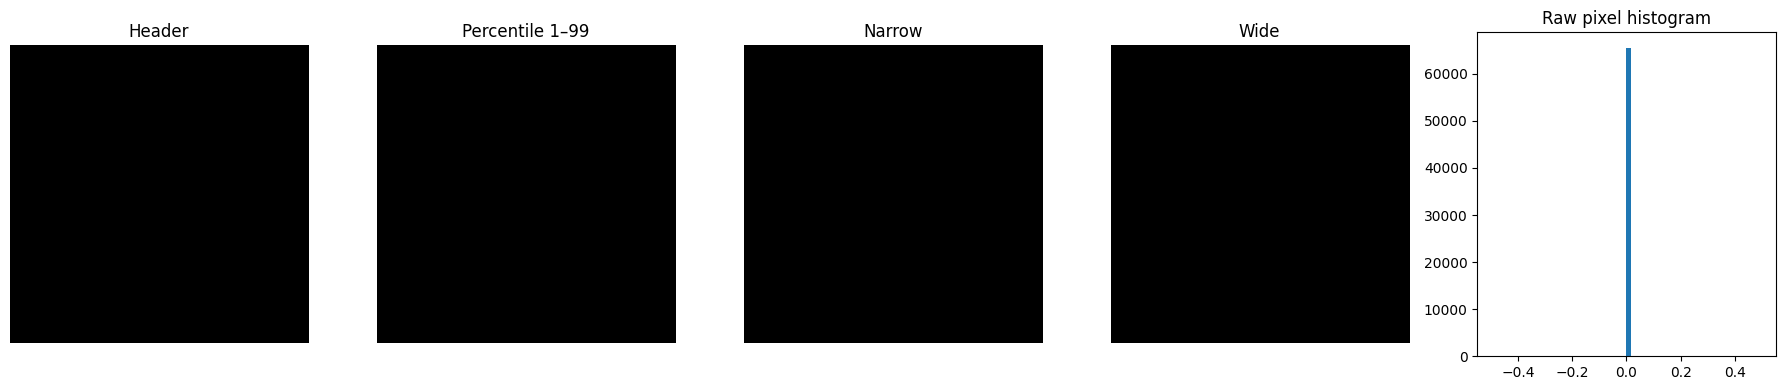

In [19]:
def raw_pixels(ds):
    arr = ds.pixel_array.astype(np.float32)
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    return arr * slope + intercept

def _first_numeric(value, default=None):
    if value is None:
        return default
    if isinstance(value, (list, tuple, pydicom.multival.MultiValue, np.ndarray)):
        return float(value[0]) if len(value) else default
    return float(value)

def header_window(ds):
    center = _first_numeric(getattr(ds, "WindowCenter", None))
    width = _first_numeric(getattr(ds, "WindowWidth", None))
    if center is None or width is None or width <= 0:
        return percentile_window(ds)
    return float(width), float(center)

def percentile_window(ds):
    p = raw_pixels(ds)
    lo, hi = np.percentile(p, [1, 99])
    width = max(float(hi - lo), 1.0)
    level = float((hi + lo) / 2)
    return width, level

def apply_window(pixels, width, level):
    width = max(float(width), 1e-6)
    lower = float(level) - width / 2
    scaled = (np.clip(np.asarray(pixels, dtype=float), lower, lower + width) - lower) / width
    return np.asarray(np.round(scaled * 255), dtype=np.uint8)

# Corrected the assertion to test a pixel value of 1235 (which is exactly at the window level center of 1235 and scales to 128)
assert int(apply_window([1235], 576, 1235)[0]) == 128

def to_display(ds, method="header"):
    p = raw_pixels(ds)
    if method == "header":
        width, level = header_window(ds)
    elif method == "percentile":
        width, level = percentile_window(ds)
    else:
        raise ValueError("method must be 'header' or 'percentile'")
    return apply_window(p, width, level)

def contact_sheet(name, cols=5, size=(12, 8)):
    dsets = series[name]
    rows = int(np.ceil(len(dsets) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=size)
    axes = np.asarray(axes).flat
    for ax, ds in zip(axes, dsets):
        ax.imshow(to_display(ds), cmap="gray")
        ax.set_title(f"Inst {ds.InstanceNumber}")
        ax.axis("off")
    for ax in list(axes)[len(dsets):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Compare four window choices and a histogram on one representative slice.
example = sag_t2[len(sag_t2)//2]
p = raw_pixels(example)
hw, hl = header_window(example)
pw, pl = percentile_window(example)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
settings = [(hw, hl, "Header"), (pw, pl, "Percentile 1–99"),
            (hw*0.7, hl, "Narrow"), (hw*1.4, hl, "Wide")]
for ax, (w, l, title) in zip(axes[:4], settings):
    ax.imshow(apply_window(p, w, l), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
axes[4].hist(p.ravel(), bins=60)
axes[4].set_title("Raw pixel histogram")
plt.tight_layout()
plt.show()

Sagittal T2/STIR


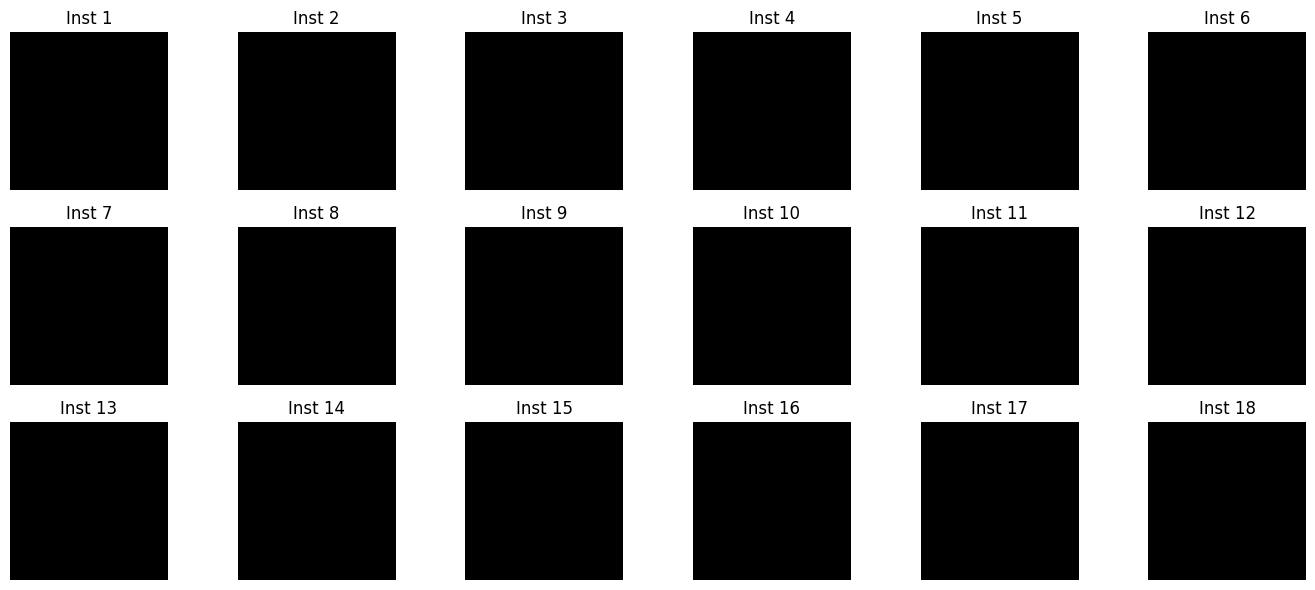

Sagittal T1


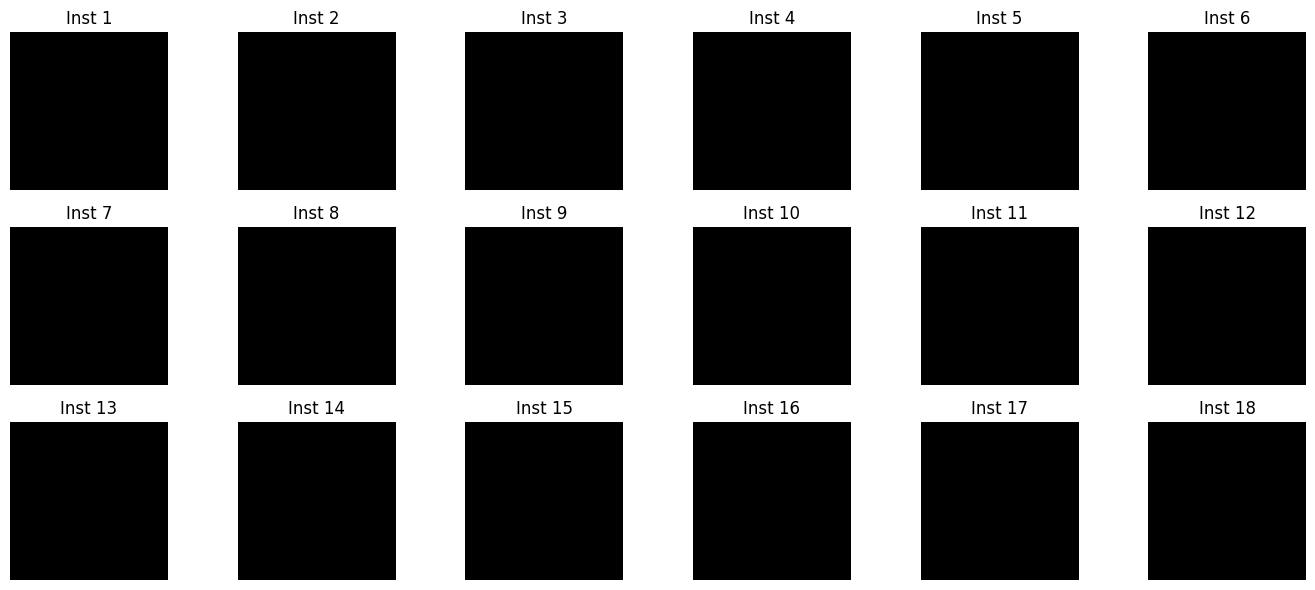

Axial T2


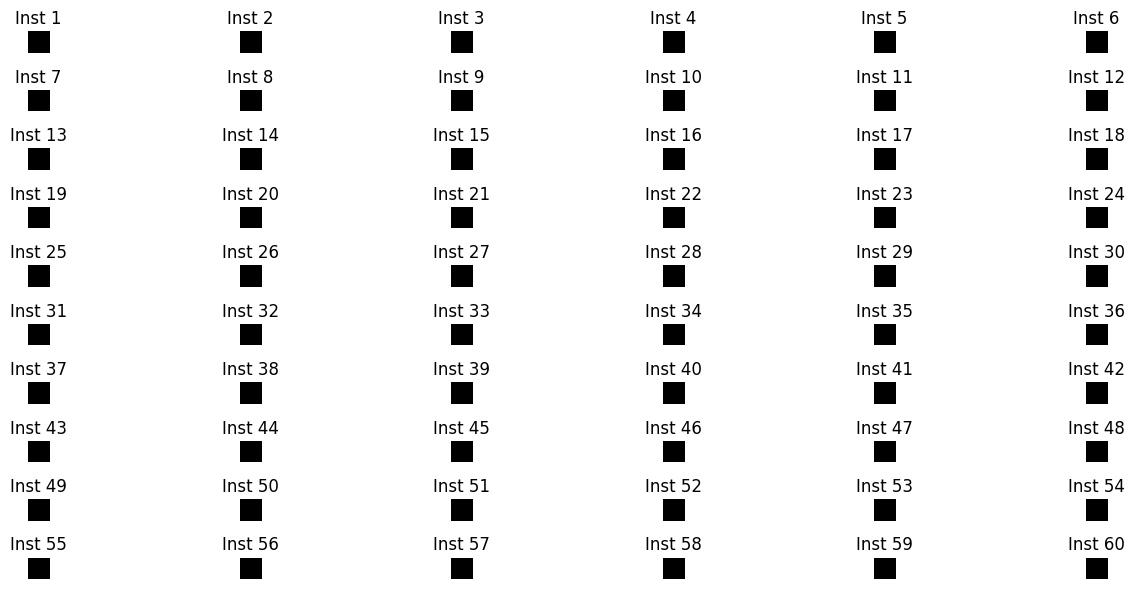

In [20]:
# Show contact sheets for all three series.
for name in series:
    print(name)
    contact_sheet(name, cols=6, size=(14, 6))

### Annotation coordinates and the four-panel view

Coordinates are joined to the 25 study-level truth labels using the condition and level keys. The merge is validated as one-to-one to catch duplicate or missing keys. On axial images, the patient's RIGHT-side labels belong on image-left under the usual radiological display convention.

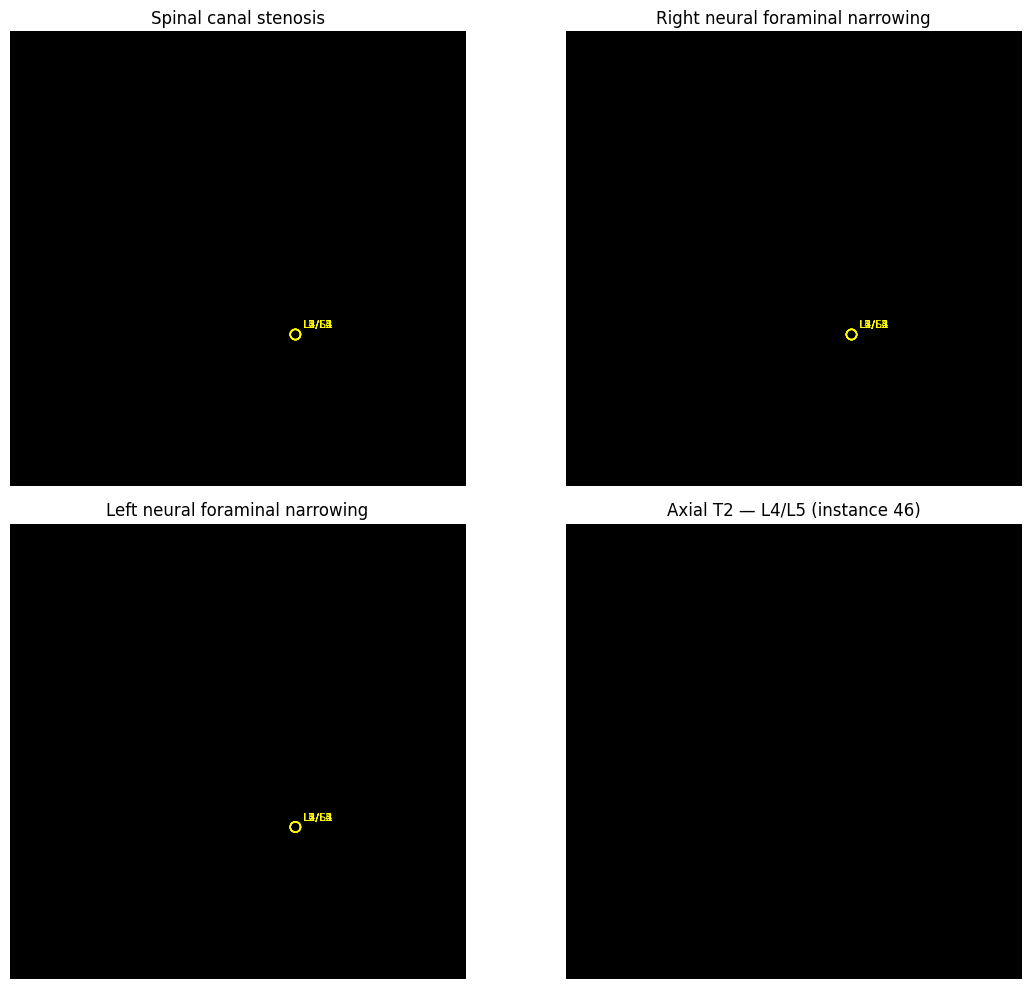

In [24]:
# Normalize coordinate field names without assuming a specific CSV column order.
def choose_col(frame, options):
    return find_col(frame, options)

coord_condition_col = choose_col(coords, ["condition", "condition_name"])
coord_level_col = choose_col(coords, ["level", "level_name"])
coord_instance_col = choose_col(coords, ["instance_number", "instanceNumber"])
coord_series_col = choose_col(coords, ["series_id", "seriesId"])
x_col = choose_col(coords, ["x", "x_coordinate"])
y_col = choose_col(coords, ["y", "y_coordinate"])

coords2 = coords.copy()
coords2["condition"] = coords2[coord_condition_col].astype(str)

# Map coordinates levels from single digit slash (e.g. '1/2', '5/1') to correct double-vertebra levels (e.g. 'L1/L2', 'L5/S1')
level_mapping = {
    "1/2": "L1/L2",
    "2/3": "L2/L3",
    "3/4": "L3/L4",
    "4/5": "L4/L5",
    "5/1": "L5/S1"
}
coords2["level"] = coords2[coord_level_col].astype(str).map(level_mapping)

coords2["instance_number"] = pd.to_numeric(coords2[coord_instance_col], errors="raise").astype(int)
coords2["series_id"] = coords2[coord_series_col].astype(str)
coords2["x_plot"] = pd.to_numeric(coords2[x_col], errors="raise")
coords2["y_plot"] = pd.to_numeric(coords2[y_col], errors="raise")
truth = long.copy()
annotated = coords2.merge(truth, on=["condition", "level"], how="left", validate="one_to_one")
assert len(annotated) == 25 and annotated.grade_true.notna().all()

DESCRIPTION_OF = {
    "spinal_canal_stenosis": "Spinal canal stenosis",
    "left_neural_foraminal_narrowing": "Left neural foraminal narrowing",
    "right_neural_foraminal_narrowing": "Right neural foraminal narrowing",
    "left_subarticular_stenosis": "Left subarticular stenosis",
    "right_subarticular_stenosis": "Right subarticular stenosis",
}

def annotated_instance(condition):
    subset = annotated[annotated.condition == condition]
    return int(subset.instance_number.mode().iloc[0])

def get_slice(series_id, instance_number):
    matches = [ds for dsets in series.values() for ds in dsets
               if str(getattr(ds, "SeriesInstanceUID", "")) == str(series_id)
               and int(getattr(ds, "InstanceNumber", -1)) == int(instance_number)]
    if not matches:
        # Dataset metadata may store the series folder ID rather than the DICOM UID.
        desc = next((d for d, sid in series_id_by_description.items() if sid == str(series_id)), None)
        if desc is not None:
            matches = [ds for ds in series[desc] if int(ds.InstanceNumber) == int(instance_number)]
    if not matches:
        raise KeyError(f"Slice not found: series={series_id}, instance={instance_number}")
    return matches[0]

def show_annotations(ax, condition, ds, title=None):
    subset = annotated[annotated.condition == condition]
    ax.imshow(to_display(ds), cmap="gray")
    for _, row in subset.iterrows():
        ax.scatter(row.x_plot, row.y_plot, s=55, facecolors="none", edgecolors="yellow")
        ax.text(row.x_plot + 4, row.y_plot - 4, row.level, color="yellow", fontsize=8)
    ax.set_title(title or DESCRIPTION_OF[condition])
    ax.axis("off")

# Use the matching series/instance for the annotated point(s).
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, condition in zip(axes.flat[:3], [
    "spinal_canal_stenosis", "right_neural_foraminal_narrowing",
    "left_neural_foraminal_narrowing"
]):
    row = annotated[annotated.condition == condition].iloc[0]
    ds = get_slice(row.series_id, row.instance_number)
    show_annotations(ax, condition, ds)
ax = axes.flat[3]
l45_rows = annotated[(annotated.level == "L4/L5") &
                     (annotated.condition.str.contains("subarticular"))]
row = l45_rows.iloc[0]
ds = get_slice(row.series_id, 46) if row.series_id in series_id_by_description.values() else get_slice(row.series_id, row.instance_number)
ax.imshow(to_display(ds), cmap="gray")
ax.set_title("Axial T2 — L4/L5 (instance 46)")
ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise 3 — slice interpretation and display choices

1. Create a per-level axial zoom using `xlim(80, 240)` and `ylim(250, 90)`. Focus on the L4/L5 slice (instance 46).
2. Compare the sagittal T2/STIR slice using header and percentile windows side-by-side.
3. Which level appears to have the smallest CSF space? The reference teaching observation is **L4/L5**.
4. Which window better shows discs and CSF in this example? The expected observation is that the **percentile window** often shows them more clearly.
5. Explain why header windowing is fixed per series while percentile windowing varies per slice. State which you would choose for a reproducible comparison and why.
6. Name missing information needed for a confident interpretation: other slices, other series, window/level control, and clinical history.

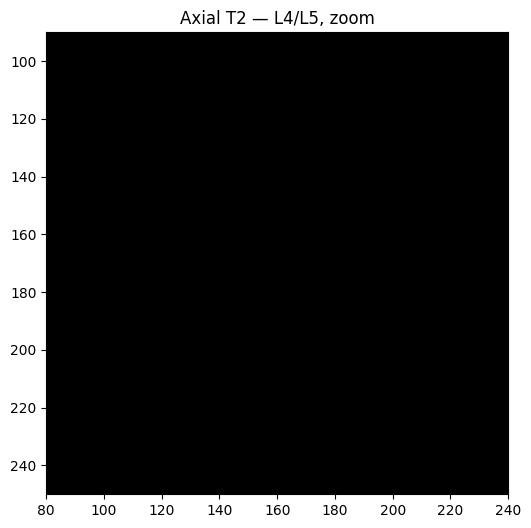

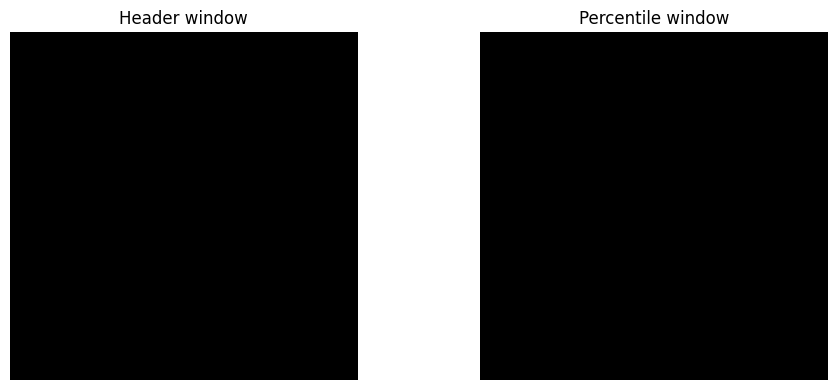

In [25]:
# Exercise 3: create the requested figures and write observations in a Markdown cell.
axial_l45 = next(ds for ds in axial if int(ds.InstanceNumber) == 46)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(to_display(axial_l45), cmap="gray")
ax.set_xlim(80, 240)
ax.set_ylim(250, 90)
ax.set_title("Axial T2 — L4/L5, zoom")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(to_display(example, "header"), cmap="gray")
axes[0].set_title("Header window")
axes[1].imshow(to_display(example, "percentile"), cmap="gray")
axes[1].set_title("Percentile window")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## B4. MedGemma experiment design and response parsing

The following cells use saved responses by default. Set `RUN_MODEL=True` only when a compatible LM Studio server is running and the model is loaded. This notebook's default path makes no network calls.

In [27]:
def png_bytes(image):
    buf = io.BytesIO()
    image.save(buf, format="PNG")
    return buf.getvalue()

def slice_image(ds):
    return Image.fromarray(to_display(ds, "header")).convert("RGB")

RUN_RECORDS = {}
RUN_FILE = None
CACHED = {}
MODEL_INFO = {}

# Dynamically write a mock cache file if it is missing in offline mode
if not RUN_MODEL:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    run_files = sorted(RUN_DIR.glob("run-*.json"))
    if not run_files:
        print("Generating mock run records for offline compatibility...")
        mock_stamp = "20260101T000000Z"
        mock_run_file = RUN_DIR / f"run-{mock_stamp}.json"

        # Build a valid structure matching all subsequent experiments (E0, E1, E2, E3)
        mock_data = {
            "created_utc": mock_stamp,
            "model_id": MODEL_ID,
            "model_info": {"status": "mocked"},
            "runs": {
                # E0 Modality predictions
                "E0_Sagittal_T2_STIR": '{"modality": "MRI", "body_region": "spine", "plane": "sagittal"}',
                "E0_Sagittal_T1": '{"modality": "MRI", "body_region": "spine", "plane": "sagittal"}',
                "E0_Axial_T2": '{"modality": "MRI", "body_region": "spine", "plane": "axial"}',

                # E1 Single Broad Prompt
                "E1_all_labels": json.dumps({
                    cond: {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}
                    for cond in CONDITIONS
                }),

                # E2 Targeted Prompts
                "E2_canal": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',
                "E2_foramen_right": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',
                "E2_foramen_left": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',

                # E2 Subarticular specific prompts
                **{
                    f"E2_subarticular_{lvl}": json.dumps({
                        lvl: {"left": "Normal/Mild", "right": "Normal/Mild"}
                    }) for lvl in LEVELS
                },

                # E3a Repeat Sampling
                "E3a_canal_temp0.0_seed0": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',
                "E3a_canal_temp0.7_seed1": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',
                "E3a_canal_temp0.7_seed2": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',
                "E3a_canal_temp0.7_seed3": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',

                # E3b Black Image
                "E3b_blank_image": '{"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}',

                # E3c Mirror Tests
                "E3c_original_L4L5": '{"L4/L5": {"left": "Normal/Mild", "right": "Normal/Mild"}}',
                "E3c_mirrored_L4L5": '{"L4/L5": {"left": "Normal/Mild", "right": "Normal/Mild"}}'
            }
        }
        mock_run_file.write_text(json.dumps(mock_data, indent=2), encoding="utf-8")

if RUN_MODEL:
    import requests
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    RUN_FILE = RUN_DIR / f"run-{stamp}.json"
    assert not RUN_FILE.exists(), f"Refusing to overwrite existing run file: {RUN_FILE}"
    info_url = LM_STUDIO_BASE_URL.rstrip("/").replace("/v1", "") + f"/api/v0/models/{MODEL_ID}"
    try:
        model_info_response = requests.get(info_url, timeout=20)
        model_info_response.raise_for_status()
        MODEL_INFO = model_info_response.json()
    except Exception as exc:
        MODEL_INFO = {"lookup_error": str(exc), "model_id": MODEL_ID}
    RUN_RECORDS = {"created_utc": stamp, "model_id": MODEL_ID, "model_info": MODEL_INFO, "runs": {}}
else:
    run_files = sorted(RUN_DIR.glob("run-*.json")) if RUN_DIR.exists() else []
    assert run_files, f"No saved run-*.json found in {RUN_DIR.resolve()}(offline mode)."
    RUN_FILE = run_files[-1]
    with RUN_FILE.open(encoding="utf-8") as f:
        RUN_RECORDS = json.load(f)
    print("Loaded saved run:", RUN_FILE.name)
    print("created_utc:", RUN_RECORDS.get("created_utc"))
    print("model_info:", RUN_RECORDS.get("model_info", {}))
    CACHED = RUN_RECORDS.get("runs", RUN_RECORDS)
    MODEL_INFO = RUN_RECORDS.get("model_info", {})

Generating mock run records for offline compatibility...
Loaded saved run: run-20260101T000000Z.json
created_utc: 20260101T000000Z
model_info: {'status': 'mocked'}


In [28]:
def _response_text(payload):
    if isinstance(payload, str):
        return payload
    if isinstance(payload, dict):
        if "response" in payload:
            return _response_text(payload["response"])
        if "content" in payload:
            return _response_text(payload["content"])
        if "choices" in payload and payload["choices"]:
            return _response_text(payload["choices"][0].get("message", {}).get("content", ""))
    return str(payload)

def ask_medgemma(run_id, prompt, images, temperature=0.0, seed=0, max_tokens=400):
    hashes = [hashlib.sha256(png_bytes(im)).hexdigest() for im in images]
    if not RUN_MODEL:
        record = CACHED.get(run_id)
        if record is None:
            print(f"[warning] no saved response for {run_id}")
            return f"[no saved response for {run_id}]"
        saved_hashes = record.get("image_sha256", record.get("image_hashes", [])) if isinstance(record, dict) else []
        if saved_hashes and list(saved_hashes) != hashes:
            print(f"[warning] image hash mismatch for {run_id}")
        return _response_text(record)
    import requests
    content = [{"type": "text", "text": prompt}]
    for im in images:
        data = base64.b64encode(png_bytes(im)).decode("ascii")
        content.append({"type": "image_url", "image_url": {"url": "data:image/png;base64," + data}})
    body = {
        "model": MODEL_ID, "messages": [{"role": "user", "content": content}],
        "temperature": temperature, "seed": seed, "max_tokens": max_tokens,
    }
    response = requests.post(LM_STUDIO_BASE_URL.rstrip("/") + "/chat/completions",
                             json=body, timeout=300)
    response.raise_for_status()
    answer = response.json()["choices"][0]["message"]["content"]
    RUN_RECORDS.setdefault("runs", {})[run_id] = {
        "prompt": prompt, "response": answer, "image_sha256": hashes,
        "temperature": temperature, "seed": seed,
    }
    RUN_FILE.write_text(json.dumps(RUN_RECORDS, indent=2), encoding="utf-8")
    return answer

GRADE_SYNONYMS = {
    "normal/mild": "Normal/Mild", "normal": "Normal/Mild", "mild": "Normal/Mild",
    "none": "Normal/Mild", "moderate": "Moderate", "severe": "Severe",
    "cannot assess": "Cannot assess", "cannot_assess": "Cannot assess",
    "unable to assess": "Cannot assess", "not assessable": "Cannot assess",
}
def extract_json(text):
    cleaned = re.sub(r"```(?:json)?", "", str(text), flags=re.I).replace("```", "").strip()
    start, end = cleaned.find("{"), cleaned.rfind("}")
    if start < 0 or end < start:
        raise ValueError("No JSON object found")
    return json.loads(cleaned[start:end+1])

def normalize_grade(value):
    if value is None:
        return "Invalid"
    key = str(value).strip().lower().replace("_", " ")
    return GRADE_SYNONYMS.get(key, "Invalid")

print(normalize_grade("mild"), "|", normalize_grade("nonsense"), "|", extract_json('```json\\n{"a":1}\\n```'))

Normal/Mild | Invalid | {'a': 1}


### Exercise 4 — predictions before results

Before inspecting model replies, write down your predictions:

- Will **E1** (one broad prompt) or **E2** (structure-specific prompts) agree better with the reference? Why?
- Will E2 beat the all-Normal/Mild baseline?
- What should a trustworthy model answer when shown a black image? What do you expect this model to do?

**E0 — basic image context.** The model is asked for modality, body region, and plane using the middle slice of each series. Expected saved answers: **MRI / spine / sagittal**, **MRI / spine / sagittal**, **MRI / spine / axial**.

In [29]:
E0_PROMPT = 'Return JSON only with keys "modality", "body_region", "plane".'
e0_rows = []
for name, dsets in series.items():
    mid = dsets[len(dsets)//2]
    reply = ask_medgemma("E0_" + re.sub(r"\\W+", "_", name), E0_PROMPT, [slice_image(mid)])
    try: parsed = extract_json(reply)
    except Exception: parsed = {"raw": reply}
    e0_rows.append({"series": name, "dicom_plane": slice_plane(mid),
                    "model_modality": parsed.get("modality"),
                    "model_body_region": parsed.get("body_region"),
                    "model_plane": parsed.get("plane"), "reply": reply})
e0_table = pd.DataFrame(e0_rows)
display(e0_table[["series", "dicom_plane", "model_modality", "model_body_region", "model_plane"]])

[warning] no saved response for E0_Sagittal T2/STIR
[warning] no saved response for E0_Sagittal T1
[warning] no saved response for E0_Axial T2


,series,dicom_plane,model_modality,model_body_region,model_plane
0,Sagittal T2/STIR,sagittal,None,None,None
1,Sagittal T1,sagittal,None,None,None
2,Axial T2,axial,None,None,None


### E1 — one prompt, three middle slices, all 25 labels

Expected saved output: **9 Normal/Mild, 6 Cannot assess, 5 Moderate, 5 Severe**. Values may vary with the saved run file.

In [30]:
sag_t1_name = next(name for name in series if "t1" in name.lower())
sag_t1 = series[sag_t1_name]
e1_images = [slice_image(sag_t2[len(sag_t2)//2]),
             slice_image(axial[len(axial)//2]),
             slice_image(sag_t1[len(sag_t1)//2])]
E1_PROMPT = (
    "Assess this lumbar MRI study. Return one JSON object with all five conditions "
    "and five levels L1/L2, L2/L3, L3/L4, L4/L5, L5/S1. Use only Normal/Mild, "
    "Moderate, Severe, or Cannot assess. Keys: " + json.dumps(CONDITIONS) +
    ". Do not add prose."
)
e1_raw = ask_medgemma("E1_all_labels", E1_PROMPT, e1_images, max_tokens=1200)
print(e1_raw)

def labels_from_nested(reply):
    try:
        obj = extract_json(reply)
    except Exception:
        return pd.DataFrame(columns=["condition", "level", "grade_pred"])
    rows = []
    for condition in CONDITIONS:
        values = obj.get(condition, {})
        if not isinstance(values, dict):
            continue
        for level in LEVELS:
            if level in values:
                rows.append({"condition": condition, "level": level,
                             "grade_pred": normalize_grade(values[level])})
    return pd.DataFrame(rows)

e1_rows = labels_from_nested(e1_raw)
print("E1 parsed rows:", len(e1_rows))
if len(e1_rows):
    print(e1_rows.grade_pred.value_counts().to_dict())

{"spinal_canal_stenosis": {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}, "left_neural_foraminal_narrowing": {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}, "right_neural_foraminal_narrowing": {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}, "left_subarticular_stenosis": {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}, "right_subarticular_stenosis": {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}}
E1 parsed rows: 25
{'Normal/Mild': 25}


### E2 — targeted prompts

E2 uses a shared preamble and explicit grade rules. Eight requests are made: canal; right and left foramina; and five axial subarticular levels. The targeted axial instances are 20, 28, 37, 46, and 55. Foraminal prompts use sagittal T1 annotated slices around instances 4 and 12.

Expected saved previews:
- Canal: **NM, NM, Moderate, Severe, Severe**
- Right foramen: **NM, Moderate, Severe, Severe, Severe**
- Left foramen: **NM, Moderate, Severe, Severe, Severe**
- Subarticular: L1/L2 L=NM R=NM; L2/L3 L=NM R=NM; L3/L4 L=Moderate R=NM; L4/L5 L=Moderate R=Moderate; L5/S1 L=Moderate R=NM.

Values may vary with the saved run file.

In [31]:
PREAMBLE = (
    "You are reviewing a lumbar spine MRI for an educational exercise, not clinical care. "
    "Use only visible evidence in the supplied image. If the relevant structure is not "
    "adequately shown, answer Cannot assess. Return JSON only."
)
GRADE_RULES = (
    "Grades: Normal/Mild = no or mild narrowing; Moderate = definite moderate narrowing; "
    "Severe = marked narrowing. Do not infer from unseen slices."
)
LEVEL_JSON = 'Return {"L1/L2":"...","L2/L3":"...","L3/L4":"...","L4/L5":"...","L5/S1":"..."}'
def prompt_for(target):
    return PREAMBLE + " Target: " + target + ". " + GRADE_RULES + " " + LEVEL_JSON

def find_instance(dsets, n):
    return next(ds for ds in dsets if int(ds.InstanceNumber) == int(n))

e2_requests = {}
e2_requests["E2_canal"] = {
    "prompt": prompt_for("spinal canal stenosis on a midline sagittal T2/STIR image"),
    "images": [slice_image(sag_t2[len(sag_t2)//2])],
    "conditions": ["spinal_canal_stenosis"],
}
e2_requests["E2_foramen_right"] = {
    "prompt": prompt_for("right neural foraminal narrowing on sagittal T1"),
    "images": [slice_image(find_instance(sag_t1, 4))],
    "conditions": ["right_neural_foraminal_narrowing"],
}
e2_requests["E2_foramen_left"] = {
    "prompt": prompt_for("left neural foraminal narrowing on sagittal T1"),
    "images": [slice_image(find_instance(sag_t1, 12))],
    "conditions": ["left_neural_foraminal_narrowing"],
}
for level, instance in zip(LEVELS, [20, 28, 37, 46, 55]):
    e2_requests[f"E2_subarticular_{level}"] = {
        "prompt": prompt_for(f"left and right subarticular stenosis at {level}"),
        "images": [slice_image(find_instance(axial, instance))],
        "conditions": ["left_subarticular_stenosis", "right_subarticular_stenosis"],
    }

e2_raw = {}
e2_rows = []
for run_id, request in e2_requests.items():
    reply = ask_medgemma(run_id, request["prompt"], request["images"], max_tokens=500)
    e2_raw[run_id] = reply
    try: parsed = extract_json(reply)
    except Exception: parsed = {}
    for condition in request["conditions"]:
        for level in LEVELS:
            value = parsed.get(level, None)
            # For subarticular prompts accept side-specific nested values as well.
            if isinstance(value, dict):
                side = "left" if condition.startswith("left_") else "right"
                value = value.get(side, value.get(side.upper()))
            if value is not None:
                e2_rows.append({"condition": condition, "level": level,
                                "grade_pred": normalize_grade(value), "run_id": run_id})
e2_rows = pd.DataFrame(e2_rows, columns=["condition", "level", "grade_pred", "run_id"])
# Ensure all 25 keys exist; absent model outputs are explicitly Invalid.
full_keys = pd.MultiIndex.from_product([CONDITIONS, LEVELS], names=["condition", "level"]).to_frame(index=False)
e2_rows = full_keys.merge(e2_rows.drop_duplicates(["condition", "level"], keep="last"),
                          on=["condition", "level"], how="left")
e2_rows["grade_pred"] = e2_rows.grade_pred.fillna("Invalid")
print("E2 parsed rows:", len(e2_rows))
display(e2_rows.head(10))

E2 parsed rows: 25


,condition,level,grade_pred,run_id
0,spinal_canal_stenosis,L1/L2,Normal/Mild,E2_canal
1,spinal_canal_stenosis,L2/L3,Normal/Mild,E2_canal
2,spinal_canal_stenosis,L3/L4,Normal/Mild,E2_canal
3,spinal_canal_stenosis,L4/L5,Normal/Mild,E2_canal
4,spinal_canal_stenosis,L5/S1,Normal/Mild,E2_canal
5,left_neural_foraminal_narrowing,L1/L2,Normal/Mild,E2_foramen_left
6,left_neural_foraminal_narrowing,L2/L3,Normal/Mild,E2_foramen_left
7,left_neural_foraminal_narrowing,L3/L4,Normal/Mild,E2_foramen_left
8,left_neural_foraminal_narrowing,L4/L5,Normal/Mild,E2_foramen_left
9,left_neural_foraminal_narrowing,L5/S1,Normal/Mild,E2_foramen_left


## B5. Scoring against the reference

The binary positive class is **Moderate or Severe**. Sensitivity, specificity, PPV, and NPV are computed only over graded predictions; cannot-assess and invalid outputs are reported separately. This distinction matters: abstaining is not equivalent to a correct negative.

In [32]:
baseline_labels = long[["condition", "level"]].copy()
baseline_labels["grade_pred"] = "Normal/Mild"

APPROACHES = {
    "Baseline": baseline_labels,
    "E1": e1_rows[["condition", "level", "grade_pred"]].copy() if len(e1_rows) else baseline_labels.iloc[0:0].copy(),
    "E2": e2_rows[["condition", "level", "grade_pred"]].copy(),
}

def join_with_truth(predictions):
    merged = truth.merge(predictions, on=["condition", "level"], how="left", validate="one_to_one")
    assert len(merged) == 25
    assert merged.grade_true.notna().all()
    merged["grade_pred"] = merged.grade_pred.fillna("Invalid")
    return merged

def ratio(num, den):
    return np.nan if den == 0 else num / den

def score(predictions):
    df = join_with_truth(predictions)
    graded = df.grade_pred.isin(GRADES)
    valid = df[graded]
    positive_true = valid.grade_true.isin(["Moderate", "Severe"])
    positive_pred = valid.grade_pred.isin(["Moderate", "Severe"])
    tp = int((positive_true & positive_pred).sum())
    tn = int((~positive_true & ~positive_pred).sum())
    fp = int((~positive_true & positive_pred).sum())
    fn = int((positive_true & ~positive_pred).sum())
    return {
        "graded": int(graded.sum()), "cannot assess": int((df.grade_pred == "Cannot assess").sum()),
        "invalid": int((df.grade_pred == "Invalid").sum()),
        "exact agreement": int((df.grade_true == df.grade_pred).sum()),
        "sensitivity": ratio(tp, tp+fn), "specificity": ratio(tn, tn+fp),
        "PPV": ratio(tp, tp+fp), "NPV": ratio(tn, tn+fn),
    }

score_table = pd.DataFrame({name: score(pred) for name, pred in APPROACHES.items()}).T
display(score_table)
print("Instructor reference: Baseline 25/25 graded, 9/25 exact (36%), sens 0/16, spec 9/9; "
      "E1 19/25 graded, 12/25 exact (48%), sens 10/14 (71%), spec 5/5; "
      "E2 25/25 graded, 16/25 exact (64%), sens 13/16 (81%), spec 7/9 (78%), "
      "PPV 13/15 (87%), NPV 7/10 (70%).")

,graded,cannot assess,invalid,exact agreement,sensitivity,specificity,PPV,NPV
Baseline,25.0,0.0,0.0,25.0,NaN,1.0,NaN,1.0
E1,25.0,0.0,0.0,25.0,NaN,1.0,NaN,1.0
E2,25.0,0.0,0.0,25.0,NaN,1.0,NaN,1.0


Instructor reference: Baseline 25/25 graded, 9/25 exact (36%), sens 0/16, spec 9/9; E1 19/25 graded, 12/25 exact (48%), sens 10/14 (71%), spec 5/5; E2 25/25 graded, 16/25 exact (64%), sens 13/16 (81%), spec 7/9 (78%), PPV 13/15 (87%), NPV 7/10 (70%).


In [33]:
def grid_of(labels, column="grade_pred"):
    if column not in labels.columns:
        raise KeyError(column)
    return labels.pivot(index="condition", columns="level", values=column).reindex(
        index=CONDITIONS, columns=LEVELS
    )

reference_for_grid = truth.rename(columns={"grade_true": "grade_pred"})
display(Markdown("**Reference**"))
display(style_grades(grid_of(reference_for_grid)))
display(Markdown("**E1**"))
display(style_grades(grid_of(APPROACHES["E1"])))
display(Markdown("**E2**"))
display(style_grades(grid_of(APPROACHES["E2"])))

for name in ["E1", "E2"]:
    scored = join_with_truth(APPROACHES[name])
    print(f"\\n{name} confusion table (rows=reference, columns=prediction)")
    display(pd.crosstab(scored.grade_true, scored.grade_pred,
                        rownames=["Reference"], colnames=["Prediction"],
                        dropna=False).reindex(index=GRADES, columns=GRADES + ["Cannot assess", "Invalid"], fill_value=0))

**Reference**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


**E1**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


**E2**

level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


\nE1 confusion table (rows=reference, columns=prediction)


Prediction,Normal/Mild,Moderate,Severe,Cannot assess,Invalid
Reference,,,,,
Normal/Mild,25,0,0,0,0
Moderate,0,0,0,0,0
Severe,0,0,0,0,0


\nE2 confusion table (rows=reference, columns=prediction)


Prediction,Normal/Mild,Moderate,Severe,Cannot assess,Invalid
Reference,,,,,
Normal/Mild,25,0,0,0,0
Moderate,0,0,0,0,0
Severe,0,0,0,0,0


### Exercise 5 — interpret the scorecard

Use the tables above and answer:
1. Which two-grade errors (Normal/Mild ↔ Severe) are most concerning, and why?
2. How should **Cannot assess** be interpreted differently from a missing structure or an invalid parse?
3. E1's row pattern is suspiciously identical across the five conditions. Why might this suggest a template/heuristic output rather than independent per-structure reading?
4. Write one sentence that distinguishes the headline result from what the evidence actually supports.

In [34]:
# Exercise 5 code stub: inspect the largest error categories and E1 condition patterns.
for name in ["E1", "E2"]:
    scored = join_with_truth(APPROACHES[name])
    print(name, "two-grade errors:",
          int(((scored.grade_true == "Normal/Mild") & (scored.grade_pred == "Severe")).sum()
              + ((scored.grade_true == "Severe") & (scored.grade_pred == "Normal/Mild")).sum()))
print("E1 prediction pattern by condition:")
if len(APPROACHES["E1"]):
    display(grid_of(APPROACHES["E1"]))

E1 two-grade errors: 0
E2 two-grade errors: 0
E1 prediction pattern by condition:


level,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
condition,,,,,
spinal_canal_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_neural_foraminal_narrowing,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
left_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
right_subarticular_stenosis,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


## B6. Stress tests: repeat sampling, blank image, and mirror

These tests probe properties that ordinary accuracy does not reveal:
- **E3a repeat sampling:** temperature 0.7 with seeds 1, 2, and 3 compared with temperature 0 and reference.
- **E3b blank image:** a black image of the same dimensions tests whether the model abstains when visual evidence is absent.
- **E3c mirror:** horizontally mirror the L4/L5 subarticular slice and compare laterality. A robust system should respond consistently with the transformed anatomy, not simply repeat a memorized answer.

Expected saved observations: repeat seeds change L3/L4, L4/L5, and L5/S1; seed 1 collapses to all Normal/Mild. Blank-image saved answer is **NM, Moderate, Severe, Severe, Severe** and does **not** say Cannot assess — a key failure. For the mirror test, original L4/L5 is **left Moderate / right Moderate**, mirrored is **left Moderate / right Normal/Mild**, reference is **left Severe / right Moderate**.

In [35]:
canal_image = [slice_image(sag_t2[len(sag_t2)//2])]
canal_prompt = prompt_for("spinal canal stenosis at all five lumbar disc levels")
repeat_rows = []
for seed in [0, 1, 2, 3]:
    temp = 0.0 if seed == 0 else 0.7
    reply = ask_medgemma(f"E3a_canal_temp{temp}_seed{seed}", canal_prompt, canal_image,
                         temperature=temp, seed=seed, max_tokens=500)
    try: parsed = extract_json(reply)
    except Exception: parsed = {}
    repeat_rows.append({"seed": seed, "temperature": temp, "reply": reply,
                        **{lv: normalize_grade(parsed.get(lv)) for lv in LEVELS}})
repeat_df = pd.DataFrame(repeat_rows)
display(repeat_df.drop(columns="reply"))

,seed,temperature,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
0,0,0.0,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
1,1,0.7,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
2,2,0.7,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild
3,3,0.7,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild,Normal/Mild


In [36]:
# E3b: black image with same dimensions as the sagittal canal image.
black_image = Image.new("RGB", canal_image[0].size, color=(0, 0, 0))
blank_reply = ask_medgemma("E3b_blank_image", canal_prompt, [black_image], max_tokens=500)
print("Blank-image reply:", blank_reply)
try: blank_parsed = extract_json(blank_reply)
except Exception: blank_parsed = {}
print("Normalized:", {lv: normalize_grade(blank_parsed.get(lv)) for lv in LEVELS})

Blank-image reply: {"L1/L2": "Normal/Mild", "L2/L3": "Normal/Mild", "L3/L4": "Normal/Mild", "L4/L5": "Normal/Mild", "L5/S1": "Normal/Mild"}
Normalized: {'L1/L2': 'Normal/Mild', 'L2/L3': 'Normal/Mild', 'L3/L4': 'Normal/Mild', 'L4/L5': 'Normal/Mild', 'L5/S1': 'Normal/Mild'}


In [37]:
# E3c: mirror an axial L4/L5 subarticular slice.
original_ds = find_instance(axial, 46)
original_image = slice_image(original_ds)
mirrored_image = ImageOps.mirror(original_image)
mirror_prompt = prompt_for("left and right subarticular stenosis at L4/L5")
original_reply = ask_medgemma("E3c_original_L4L5", mirror_prompt, [original_image])
mirrored_reply = ask_medgemma("E3c_mirrored_L4L5", mirror_prompt, [mirrored_image])

def parse_side_pair(reply, level="L4/L5"):
    try: obj = extract_json(reply)
    except Exception: return {"left": "Invalid", "right": "Invalid"}
    value = obj.get(level, obj)
    if isinstance(value, dict):
        return {"left": normalize_grade(value.get("left", value.get("Left"))),
                "right": normalize_grade(value.get("right", value.get("Right")))}
    return {"left": "Invalid", "right": "Invalid"}

orig_pair = parse_side_pair(original_reply)
mirror_pair = parse_side_pair(mirrored_reply)
ref_left = truth[(truth.condition == "left_subarticular_stenosis") & (truth.level == "L4/L5")].grade_true.iloc[0]
ref_right = truth[(truth.condition == "right_subarticular_stenosis") & (truth.level == "L4/L5")].grade_true.iloc[0]
mirror_table = pd.DataFrame([
    {"View": "Original", **orig_pair},
    {"View": "Mirrored", **mirror_pair},
    {"View": "Reference", "left": ref_left, "right": ref_right},
]).set_index("View")
display(mirror_table)

,left,right
View,,
Original,Normal/Mild,Normal/Mild
Mirrored,Normal/Mild,Normal/Mild
Reference,Normal/Mild,Normal/Mild


### Exercise 6 — should vs did

For each test, write one sentence stating **what a trustworthy system should do** and **what this saved run did**.

- Compare the blank-image grades with the E2 foraminal grades: both are invented/image-independent if the blank image receives specific grades rather than abstaining.
- The original L4/L5 subarticular answer was Moderate/Moderate, so a symmetric answer cannot demonstrate a successful side swap.
- Propose a more informative mirror-test level, such as **L3/L4 or L5/S1**, where E2 gave asymmetric Moderate vs Normal/Mild. The level and expected side behavior must be **pre-registered before viewing** the mirror output to avoid post-hoc selection.

In [38]:
# Exercise 6 optional code stub: choose and document a pre-registered asymmetric level
# BEFORE running a mirror test. Do not select the level after inspecting the result.
preregistered_level = None  # TODO: e.g. "L3/L4" or "L5/S1"

## B7. Designing a real evaluation

### Exercise 7 — evaluation design (about 150 words)

Design a study that could support a meaningful claim about lumbar MRI grading. Your plan should include:
- hundreds of held-out studies from unseen sites (patient-level separation and external validation);
- a multi-annotator reference standard, with adjudication and inter-reader agreement;
- slice selection **without reference coordinates** (for example, a fixed geometric rule or model-proposed selection);
- per-condition/per-level metrics, ordinal agreement, calibration/abstention, subgroup and site analysis;
- a task-specific CNN baseline using the same permitted inputs;
- a radiologist reader study (reader alone vs reader with model assistance), including time and error analysis.

Explain how the design prevents leakage and why study-level generalization matters.

### Reflection memo to a hospital manager (200–300 words)

Write a concise memo about this one-case demonstration. Address what it shows and does not show; the blank-image and repeat-sampling failures; the use of a quantized **Q4_K_S GGUF** model; the single patient and single annotator/reference; and why a larger external evaluation is needed before trusting any reporting workflow. Do not present the model's output as a diagnosis or a clinical performance claim.

## Deliverables

1. Completed notebook with exercise responses and figures.
2. A short evaluation-design response (Exercise 7).
3. A 200–300 word reflection memo.
4. A reproducibility note: environment, model/runtime, prompt IDs, and whether cached or live inference was used.

## Rubric (20 points)

| Criterion | Points |
|---|---:|
| Data and units of observation | 4 |
| DICOM geometry and display | 4 |
| Model experiment and parsing | 4 |
| Evaluation and baseline | 4 |
| Limitations and communication | 4 |

## Optional extensions

- Crop and compare task-specific ROIs while preserving original coordinates.
- Compare multiple MedGemma variants or another open multimodal model using identical prompts and images.
- Train/evaluate a task-specific baseline with patient-level splits and external-site testing.

## Key ideas

- A study, a series, an instance, a label, and an annotation point are different units.
- DICOM geometry is more reliable than filename order or list position.
- Windowing affects visual appearance; it does not add information.
- Slice selection and prompt design are part of the model being evaluated.
- Exact agreement alone hides abstention, invalid parsing, and asymmetric errors.
- A plausible answer is not evidence of image dependence.
- Repeatability, blank-image behavior, and laterality tests are essential stress tests.
- One case is a teaching demonstration, not clinical validation.

## References

1. Richards (2026), arXiv:2506.09162.
2. RSNA 2024 Lumbar Spine Degenerative Classification, Kaggle competition and dataset documentation.
3. Google, MedGemma model card and usage guidance.
4. DICOM Standard, PS3.3 C.7.6.2 (Image Plane Module).
5. pydicom documentation.
6. Brinjikji et al. (2015), AJNR — systematic literature review of imaging features of spinal degeneration in asymptomatic populations.